# ICA17 - Gravitational Waves from Compact Binary Systems

Credit: <a href='https://gwosc.org/'>Gravitational Wave Open Science Center</a>

---
_Thursday, October 29, 2026_

_How to use this notebook:_

**Remote**: You can open the notebook on Colab by hovering over the rocket symbol then select launch to colab. In doing so, any data needed for the plots can be click and dragged to the online workbook.

---

## In-Class Assignment 17

## Gravitational Waves from Compact Binary Systems

### Learning Objectives

- Use GWpy to analyze open-source LIGO data
- Practice applying timeseries analysis techniques: FFT, whitening, bandpasses
- Convert whitened data to audio WAV file

## **a. - Set parameters for the signal we want to explore**

### **Individually/with the person next to you**:

The two first parameters we need to set are:

* [GPS time](https://gwosc.org/gps) of the data of interest ([Learn more](https://www.google.com/search?q=What+is+gps+time))
* Detector could be H1 (LIGO Hanford), L1 (LIGO Livingston), or V1 (Virgo)

Example GPS times for different events are:

You might try some of these examples times in the H1 detector:
<pre>
t0 = 1126259462.4    # -- GW150914
t0 = 1187008882.4    # -- GW170817
t0 = 933200215       # -- Loud hardware injection
t0 = 1132401286.33   # -- Koi Fish Glitch
</pre>

1. Choose and set a GPS time
2. Choose a detector
3. Round the GPS time to integer then query for the GW strain ($\Delta L/L$) using the integer GPS time, and the detector using [`TimeSeries.fetch_open_data`](https://gwpy.github.io/docs/stable/timeseries/opendata/#timeseries-fetch-open-data) from center to $\pm$ 16 seconds.
4. Plot the resulting strain as a function of time.

> Hint: You can call our `TimeSeries` object `strain` and use the `.plot()` object to use GWpy to plot.

In [1]:
# -- Set a GPS time:
t0 = 1126259462.4    # -- GW150914

#-- Choose detector as H1, L1, or V1
detector = 'H1'

## To Begin

Load some imports including [GWpy](https://gwpy.github.io/) - a python package for gravitational-wave astrophysics.


We will be utilizing the `TimeSeries` tools described in [Documentation](https://gwpy.github.io/docs/stable/timeseries/).

Some packages may be missing on some platforms so we try to install them (you may see error messages when running on Google Colab but installation usually works).
If you experience problems, please [report an issue](https://github.com/gwosc-tutorial/quickview/issues).

In [2]:
try:
    from gwpy.timeseries import TimeSeries
except:
    ! pip install -q "gwpy==3.0.13"
    from gwpy.timeseries import TimeSeries

import matplotlib.pyplot as plt

### Query and download data

In [3]:
center = int(t0)  #-- Round GPS time to nearest second
strain = TimeSeries.fetch_open_data(detector, center-16, center+16)

### Plot the raw time-series data

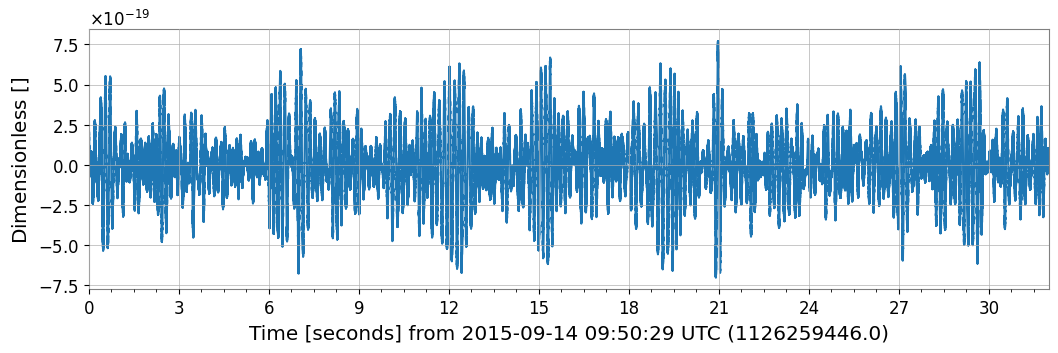

In [4]:
fig1 = strain.plot()

### Plot the Amplitude Spectral Density (ASD)

The amplitude spectral density is one way to visualize the frequency-domain content of a time series signal.
 * [ASDs in the gwpy documentation](https://gwpy.github.io/docs/stable/signal/)
 * [ASDs in Wikipedia](https://en.wikipedia.org/wiki/Spectral_density)
 * [ASDs in the Frequency Domain Data video](https://labcit.ligo.caltech.edu/~jkanner/gwosc/intro-course/)

(1e-24, 1e-19)

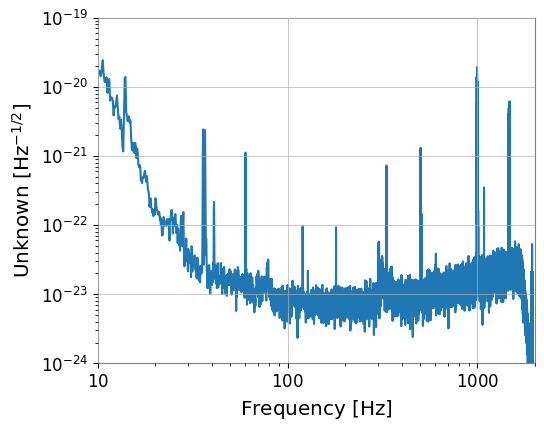

In [5]:
# -- Plot ASD
fig2 = strain.asd(fftlength=8).plot()
plt.xlim(10,2000)
plt.ylim(1e-24, 1e-19)

## **b. - Whiten and band-pass the data**


* Whitening is a process that re-weights a signal, so that all frequency bins have a nearly equal amount of noise.
* A band-pass filter uses both a low frequency cutoff and a high frequency cutoff, and only passes signals in the frequency band between these values.

See also:

 * [Whitening a TimeSeries](https://gwpy.github.io/docs/stable/examples/timeseries/whiten/#whitening-a-timeseries)
 * [Signal Processing Tutorial](https://gwfilter.streamlit.app)
 * [Finding Signals in Noise video](https://labcit.ligo.caltech.edu/~jkanner/gwosc/intro-course/)


### **Individually/with the person next to you**:

1. Createn a new array of the whitened strain data using the [`whiten` tool](https://gwpy.github.io/docs/stable/api/gwpy.timeseries.TimeSeries/#gwpy.timeseries.TimeSeries.whiten) on our straindata.
2. Apply a [`bandpass`](https://gwpy.github.io/docs/stable/api/gwpy.timeseries.TimeSeries/#gwpy.timeseries.TimeSeries.bandpass) to the whitened data from 30 to 400 Hz.
3. Plot the whitened and bandpassed data from (our t0 GPS time - 0.2 seconds, to our t0 GPS time + 0.1 seconds.)


(1126259462.2, 1126259462.5)

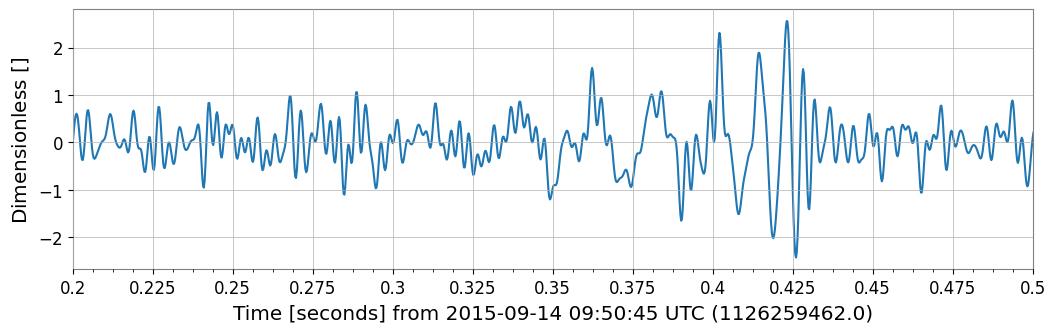

In [6]:
# -- Whiten and bandpass data
white_data = strain.whiten()
bp_data = white_data.bandpass(30, 400)
fig3 = bp_data.plot()
plt.xlim(t0-0.2, t0+0.1)

### **With your larger group, try to answer the following**:

1. In a few words, describe what is being measured over time, what is meant by graviational wave strain?

> The change in the detector arm legths relative to the known length over time.

2. Binary Black Hole (BBH) mergers have distinct epochs corresponding to - inspiral, merger, and ringdown. Can we identify those parts of the signal in the above plot?

> From left to right - inspiral (long term), merger (very short), ringdown (less short, ringdown of BH formed).

3. Single massive stars can produce graviational wave signals during _core bounce_ following iron core-collapse, how might we expect GWs from massive stars to differ?

> Only burst signals, no leading up inspiral signal that could be in LIGO bandpass and trigger detection.

4. Would BBH mergers or GWs from single, massive stars be easier to observe?

> Harder, less compact, less energetic GW bursts, need to be very nearby.

5. What is another merger scenario that would follow the signal behavior like in Question 1 for BBH?

> BNS systems.

## **c. - Plot a q-transform of the data**

A Q-transform plot shows how a signal’s frequency changes with time.

* The x-axis shows time
* The y-axis shows frequency
* The color scale shows the amount of “energy” or “signal power” in each time-frequency pixel.

A parameter called “Q” refers to the quality factor. A higher quality factor corresponds to a larger number of cycles in each time-frequency pixel.

* [Q-transform in gwpy](https://gwpy.github.io/docs/latest/examples/timeseries/qscan/)
* [Q-transform in Wikipedia](https://en.wikipedia.org/wiki/Constant-Q_transform)

### **Individually/with the person next to you**:

1. Using a `dt=1`, use GWpy to apply a [`q-transform`] with an out segment of $t_{0}\pm dt$.
2. Plot the resulting transformation using the GWpy native plotting tool. Make sure y-scale is set to log.

> Hint: Compare with [Figure 2](https://journals.aps.org/prl/pdf/10.1103/PhysRevLett.116.061102).

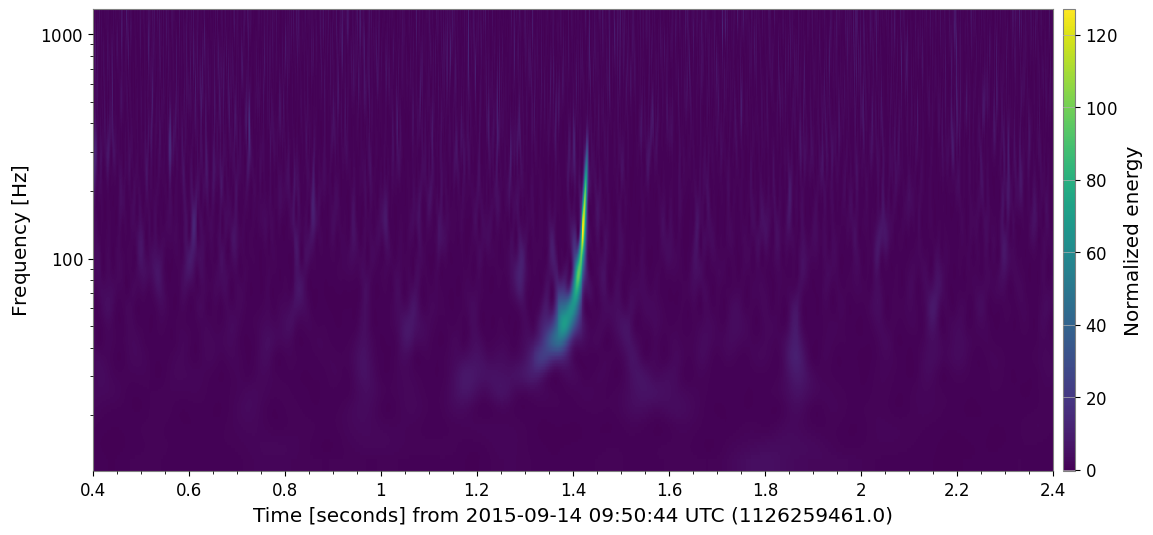

In [7]:
dt = 1  #-- Set width of q-transform plot, in seconds
hq = strain.q_transform(outseg=(t0-dt, t0+dt))
fig4 = hq.plot()
ax = fig4.gca()
ax.grid(False)
ax.set_yscale('log')
try: fig4.colorbar(label="Normalized energy")
except: pass

### Some helper functions for `d`

In [8]:
# function to keep the data within integer limits, and write to wavfile:
def write_wavfile(filename,fs,data):
    d = np.int16(data/np.max(np.abs(data)) * 32767 * 0.9)
    wavfile.write(filename,int(fs), d)

deltat_sound = 2.                     # seconds around the event

# function that shifts frequency of a band-passed signal
def reqshift(data,fshift=100,sample_rate=4096):
    """Frequency shift the signal by constant
    """
    x = np.fft.rfft(data)
    T = len(data)/float(sample_rate)
    df = 1.0/T
    nbins = int(fshift/df)
    # print T,df,nbins,x.real.shape
    y = np.roll(x.real,nbins) + 1j*np.roll(x.imag,nbins)
    y[0:nbins]=0.
    z = np.fft.irfft(y)
    return z

## **d. - Convert the data to audio**


### **Individually/with the person next to you**:

1. Define the time array of our final bandpassed and whitened strain data. We only want the data not the units (`.value`). Use `tevent = t0`. Compute the indices of interested and write the wav file for our data.

2. Listen to the data wav file.

3. Finally, shift the data using the function line, write the wav file of the shifted data.

4. Listen to the result.

In [9]:
# make wav (sound) files from the whitened+BP data, +-2s around the event.
import scipy
import numpy as np
from scipy.io import wavfile
from IPython.display import Audio

### Listening to the Whitened-Bandpassed Strain Data in the original Frequency Range

In [10]:
time = bp_data.times
time = time.value
tevent = t0
fs = 4096 # sampling freq

# index into the strain time series for this time interval:
indxd = np.where((time >= tevent-deltat_sound) & (time < tevent+deltat_sound))

# write the files:
write_wavfile(detector+"_whitenbp.wav",int(fs), strain[indxd])

In [11]:
# listen to the wav file here
fna = detector+"_whitenbp.wav"
print(fna)
Audio(fna)

H1_whitenbp.wav


### Listening to the frequency shifted Whitened-Bandpassed Strain Data

In [12]:
# using our helper function, shift the data and make the new wav file
fshift = 400.
strain_shifted = reqshift(bp_data,fshift=fshift,sample_rate=fs)
write_wavfile(detector+"_whitenbp_shifted.wav",int(fs), strain_shifted[indxd])

In [13]:
# listen to the wav file here
fna = detector+"_whitenbp_shifted.wav"
print(fna)
Audio(fna)

H1_whitenbp_shifted.wav


### **With your larger group, try to answer the following**:

1. Can you describe qualitatively what the frequency shifted sample sounded like?

> The chirp heard around the world.

2. This result shows that as the stars coalesce, their frequency increases over time. What might this suggest for sources near the LIGO bandwith?

> they can move outside the band prior to merger and avoid detection.

3. Stars that produce stellar mass BHs are rarer than those that produce neutron stars, yet, the majority of LIGO sources are BBH mergers. Why might that be?

> Orbital decay of BBHs is more significant so inspiral times are shorter and coalesce more often.